# Spaceship Titanic | Proyecto completo de Machine Learning

**Universidad Nacional Autónoma de México — FES Acatlán**  
**Licenciatura en Matemáticas Aplicadas y Computación**  
**Materia:** Sistemas Inteligentes  
**Alumno:** Christian Gabriel Villafuerte Aguilar  
**Fecha:** octubre de 2026

## Objetivo

Predecir `Transported` (0/1), optimizando el **F1-score positivo** sin dejar de reportar *accuracy, precision, recall, especificidad, F1 macro, balanced accuracy, ROC-AUC, PR-AUC y log loss*.

**Metodología:** comprensión del problema → auditoría de datos → limpieza → ingeniería de características → separación de conjuntos → imputación y codificación → normalización/escalado → validación cruzada → ajuste → evaluación independiente → exportación.

**Fuentes didácticas incluidas:** `U5 - 01 - ML.pdf` (aprendizaje supervisado), `U5 - 02 - Perceptrón.pdf` (clasificadores), `03 - Ciclo de vida del ML.pdf` (CRISP-DM, pipelines, leakage y métricas). **No confundir** la demostración sobre Titanic clásico de las diapositivas con este Spaceship Titanic.

> El conjunto `test.csv` no tiene etiquetas `Transported`, por lo que **no** se pueden calcular métricas reales de Kaggle sin evaluación externa. Las métricas reportadas proceden de validación interna y holdout de `train.csv`. No existe garantía de que un algoritmo sea el óptimo absoluto.

## 0. Preparación del entorno y reproducibilidad

Ejecutar de arriba a abajo (`Kernel → Restart & Run All`). Se requiere Python 3.10+ y los paquetes indicados en `requirements.txt`. Por defecto las rutas funcionan dentro de esta carpeta, sin modificar los CSV originales. Se fija la semilla para hacer reproducibles particiones y modelos. El entrenamiento consume varios minutos en CPU.

In [1]:
from pathlib import Path
import os, json, warnings, random, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, balanced_accuracy_score, log_loss,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay, roc_curve)
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import joblib

SEED = 42
np.random.seed(SEED); random.seed(SEED)
warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', palette='deep')
ROOT = Path.cwd()
if not (ROOT / 'data' / 'train.csv').exists() and (ROOT / 'Spaceship_Titanic_Proyecto_ML' / 'data' / 'train.csv').exists():
    ROOT = ROOT / 'Spaceship_Titanic_Proyecto_ML'
DATA = ROOT / 'data'; OUT = ROOT / 'resultados'; MODELS = ROOT / 'modelos'
OUT.mkdir(exist_ok=True,parents=True); MODELS.mkdir(exist_ok=True,parents=True)
print('Proyecto:',ROOT.resolve()); print('Python:',sys.version.split()[0]); print('Pandas:',pd.__version__)

Proyecto: /mnt/data/Spaceship_Titanic_Proyecto_ML
Python: 3.13.5
Pandas: 2.2.3


## 1. Comprensión de los datos

`train.csv` contiene observaciones etiquetadas; `test.csv` solo contiene variables explicativas; `sample_submission.csv` define el formato esperado por Kaggle. `PassengerId` y `Cabin` **no** son números continuos sin más: contienen información estructural que extraeremos después.

In [2]:
train_raw = pd.read_csv(DATA / 'train.csv')
test_raw = pd.read_csv(DATA / 'test.csv')
sample = pd.read_csv(DATA / 'sample_submission.csv')
assert 'Transported' in train_raw and 'Transported' not in test_raw
assert train_raw.PassengerId.is_unique and test_raw.PassengerId.is_unique
assert set(train_raw.columns) - {'Transported'} == set(test_raw.columns)
print('train:',train_raw.shape, '| test:',test_raw.shape, '| formato de envío:',sample.shape)
display(train_raw.head(6))
display(train_raw.dtypes.rename('Tipo de dato').to_frame())

train: (8693, 14) | test: (4277, 13) | formato de envío: (4277, 2)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True
5,0005_01,Earth,False,F/0/P,PSO J318.5-22,44.0,False,0.0,483.0,0.0,291.0,0.0,Sandie Hinetthews,True


,Tipo de dato
PassengerId,object
HomePlanet,object
CryoSleep,object
Cabin,object
Destination,object
Age,float64
VIP,object
RoomService,float64
FoodCourt,float64
ShoppingMall,float64


## 2. Auditoría: clases, nulos, duplicados y rangos

Seguimos la etapa de **calidad de datos** de la presentación de ciclo de vida. Antes de modificar nada, cuantificamos problemas y guardamos el resumen. No se eliminan pasajeros por tener datos faltantes.

In [3]:
def data_audit(frame, label):
    summary = pd.DataFrame({'tipo':frame.dtypes.astype(str), 'nulos':frame.isna().sum(),
                            'porcentaje_nulos':(100*frame.isna().mean()).round(2),
                            'valores_unicos':frame.nunique(dropna=True)})
    print(f'{label}: {len(frame):,} filas; {frame.duplicated().sum()} duplicados exactos; '
          f'{frame.PassengerId.duplicated().sum()} ID duplicados')
    return summary
train_audit = data_audit(train_raw,'TRAIN'); test_audit = data_audit(test_raw,'TEST')
display(train_audit)
train_audit.to_csv(OUT/'auditoria_train.csv',encoding='utf-8-sig')
test_audit.to_csv(OUT/'auditoria_test.csv',encoding='utf-8-sig')
print('Distribución target:');display(train_raw.Transported.value_counts().rename('pasajeros').to_frame())
print('Edad negativa:',int((train_raw.Age<0).sum()),'| Gastos negativos:',int((train_raw[['RoomService','FoodCourt','ShoppingMall','Spa','VRDeck']]<0).sum().sum()))

TRAIN: 8,693 filas; 0 duplicados exactos; 0 ID duplicados
TEST: 4,277 filas; 0 duplicados exactos; 0 ID duplicados


,tipo,nulos,porcentaje_nulos,valores_unicos
PassengerId,object,0,0.00,8693
HomePlanet,object,201,2.31,3
CryoSleep,object,217,2.50,2
Cabin,object,199,2.29,6560
Destination,object,182,2.09,3
Age,float64,179,2.06,80
VIP,object,203,2.34,2
RoomService,float64,181,2.08,1273
FoodCourt,float64,183,2.11,1507
ShoppingMall,float64,208,2.39,1115


Distribución target:


,pasajeros
Transported,
True,4378
False,4315


Edad negativa: 0 | Gastos negativos: 0


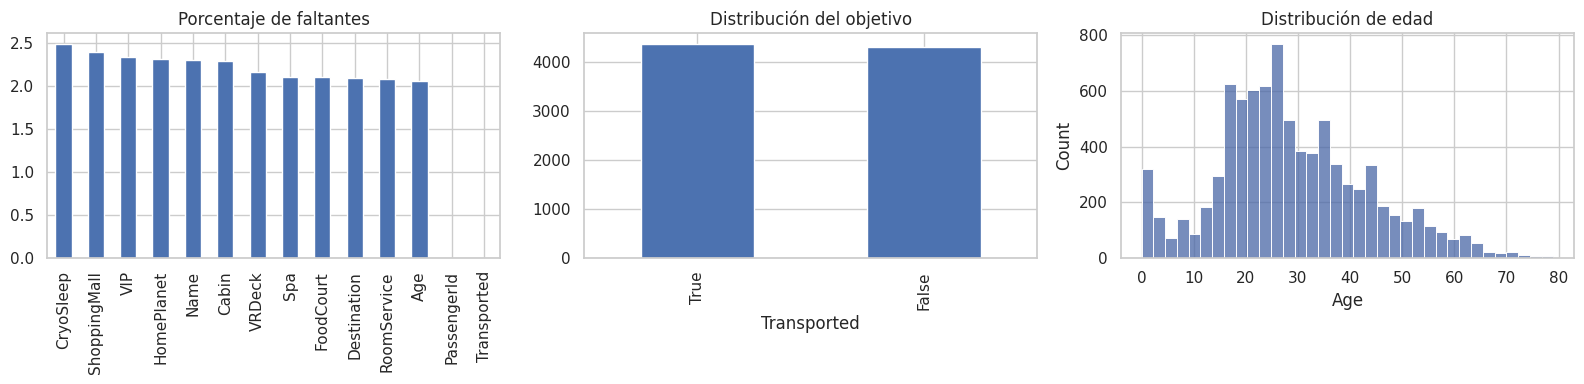

In [4]:
fig,axes=plt.subplots(1,3,figsize=(16,4))
(train_raw.isna().mean()*100).sort_values(ascending=False).plot(kind='bar',ax=axes[0],title='Porcentaje de faltantes')
train_raw.Transported.astype(str).value_counts().plot(kind='bar',ax=axes[1],title='Distribución del objetivo')
sns.histplot(train_raw['Age'],bins=35,ax=axes[2],color='#4967a6');axes[2].set_title('Distribución de edad')
fig.tight_layout();fig.savefig(OUT/'01_auditoria.png',dpi=150,bbox_inches='tight');plt.show()

## 3. Exploración de patrones, sin seleccionar variables a partir del holdout

En el análisis exploratorio podemos revisar correlaciones e hipótesis (p. ej., CryoSleep y gastos), pero no usaremos esta inspección de las etiquetas para rellenar valores faltantes ni para construir nuevas variables. Las decisiones de modelado se tomarán usando solo el conjunto de desarrollo.

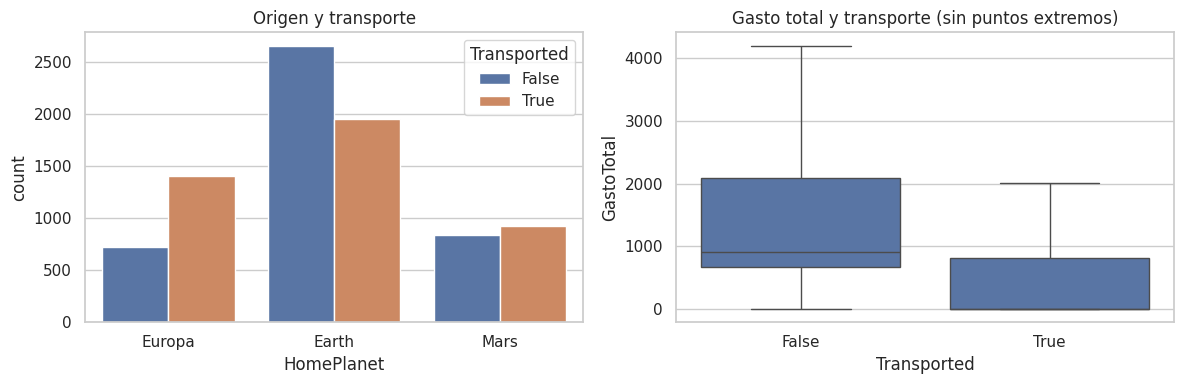

In [5]:
expenses=['RoomService','FoodCourt','ShoppingMall','Spa','VRDeck']
eda=train_raw.copy();eda['GastoTotal']=eda[expenses].sum(axis=1,min_count=1)
fig,axs=plt.subplots(1,2,figsize=(12,4))
sns.countplot(data=eda,x='HomePlanet',hue='Transported',ax=axs[0]);axs[0].set_title('Origen y transporte')
sns.boxplot(data=eda,x='Transported',y='GastoTotal',showfliers=False,ax=axs[1]);axs[1].set_title('Gasto total y transporte (sin puntos extremos)')
fig.tight_layout();fig.savefig(OUT/'02_exploracion.png',dpi=150,bbox_inches='tight');plt.show()

## 4. Limpieza coherente e ingeniería de características

**Importante:** la siguiente función usa **exclusivamente columnas de entrada**; jamás lee `Transported`. La información agregada por grupos se calcula usando los datos sin etiqueta de ambos CSV (aprendizaje transductivo: se conocen los pasajeros a predecir). No se usa ninguna etiqueta de prueba. Si se despliega con pasajeros individuales nuevos, sería necesario recalcular los agregados para ese lote.

- `PassengerId = gggg_pp` → identificador de grupo, tamaño de grupo, orden.
- `Cabin = deck/num/side` → cubierta, número, lado, sección.
- `Name` → apellido y frecuencia, sin conservar nombres de alta cardinalidad.
- `RoomService`…`VRDeck` → gasto total, gasto por tipo, proporciones y logaritmos (`log1p` disminuye asimetría).
- Edad → grupos de edad e indicadores de ausencias; booleanos se mantienen como categorías.
- `CryoSleep=True` implica gastos cero: solo se reemplazan sus gastos faltantes por cero en esa situación consistente.
- Imputación por grupo de procedencia/cabina solo cuando existe un dato no ambiguo en el grupo. El resto se resuelve **dentro de los pipelines ajustados en entrenamiento**.

In [6]:
EXPENSES = ['RoomService','FoodCourt','ShoppingMall','Spa','VRDeck']

def engineer_features(train_unlabeled, test_unlabeled):
    # Se combinan SOLO columnas predictoras, sin Transported
    joined = pd.concat([train_unlabeled, test_unlabeled],axis=0,ignore_index=True)
    n_train = len(train_unlabeled)
    d = joined.copy()
    parts = d['PassengerId'].str.split('_',expand=True)
    d['GroupID'] = parts[0]
    d['GroupOrder'] = pd.to_numeric(parts[1],errors='coerce')
    d['GroupSize'] = d.groupby('GroupID')['PassengerId'].transform('size').astype(float)
    d['TravelingAlone'] = (d['GroupSize']==1).astype(int)
    d['GroupMaxOrder'] = d.groupby('GroupID')['GroupOrder'].transform('max')
    cabin_parts = d['Cabin'].str.split('/',expand=True)
    d['Deck']=cabin_parts[0]
    d['CabinNumber']=pd.to_numeric(cabin_parts[1],errors='coerce')
    d['Side']=cabin_parts[2]
    d['CabinSector']=(d['CabinNumber']//100).astype('Float64').astype('string')
    d['CabinMissing']=d['Cabin'].isna().astype(int)
    d['Surname']=d['Name'].str.split().str[-1]
    d['SurnameFreq']=d['Surname'].map(d['Surname'].value_counts()).astype(float)
    d['NameMissing']=d['Name'].isna().astype(int)
    # Completar únicamente cuando los demás miembros del grupo coinciden
    for column in ['HomePlanet','Deck','Side']:
        consistent=d.groupby('GroupID')[column].agg(lambda s: s.dropna().iloc[0]
                       if s.dropna().nunique()==1 else np.nan)
        d[column]=d[column].fillna(d['GroupID'].map(consistent))
    for col in EXPENSES:
        d[col]=pd.to_numeric(d[col],errors='coerce').mask(lambda s:s<0)
        d.loc[d['CryoSleep'].eq(True)&d[col].isna(),col]=0.0
        d[col+'Missing']=d[col].isna().astype(int)
    d['Age']=pd.to_numeric(d['Age'],errors='coerce').mask(lambda s:(s<0)|(s>120))
    d['AgeMissing']=d['Age'].isna().astype(int)
    d['AgeBand']=pd.cut(d['Age'],bins=[-0.1,12,17,25,40,60,120],
                      labels=['Nino','Adolescente','Joven','Adulto','Mayor','Senior']).astype('object')
    d['IsChild']=np.where(d['Age'].isna(),np.nan,(d['Age']<13).astype(float))
    d['TotalSpend']=d[EXPENSES].sum(axis=1,min_count=1)
    d['LogTotalSpend']=np.log1p(d['TotalSpend'].clip(lower=0))
    d['LuxurySpend']=d[['Spa','VRDeck']].sum(axis=1,min_count=1)
    d['BasicSpend']=d[['RoomService','FoodCourt']].sum(axis=1,min_count=1)
    d['SpendCategoriesKnown']=d[EXPENSES].notna().sum(axis=1).astype(float)
    d['NumSpentServices']=(d[EXPENSES].fillna(0)>0).sum(axis=1).astype(float)
    d['ZeroSpend']=np.where(d['SpendCategoriesKnown']==len(EXPENSES),(d['TotalSpend']==0).astype(float),np.nan)
    d['AnySpend']=np.where(d['TotalSpend'].notna(),(d['TotalSpend']>0).astype(float),np.nan)
    d['SpendPerPerson']=d['TotalSpend'] / d['GroupSize']
    for col in EXPENSES:
        d['Log'+col]=np.log1p(d[col].clip(lower=0))
        d['Share'+col]=d[col]/d['TotalSpend'].replace(0,np.nan)
    # Conservar CryoSleep como variable categorica; regla de coherencia sólo si falta y hubo gasto positivo
    d.loc[d['CryoSleep'].isna() & (d['TotalSpend']>0),'CryoSleep']=False
    d['SpendsInCryo']=(d['CryoSleep'].eq(True)&(d['TotalSpend']>0)).astype(int)
    d['VIPMissing']=d['VIP'].isna().astype(int)
    # Identificadores de alta cardinalidad se eliminan: no usar ID/grupo crudo como predictor.
    d=d.drop(columns=['PassengerId','GroupID','Cabin','Name','Surname'])
    for col in d.select_dtypes(include=['object','string','category']).columns:
        d[col]=d[col].fillna('Desconocido').astype(str)
    return d.iloc[:n_train].reset_index(drop=True), d.iloc[n_train:].reset_index(drop=True)

X_all, X_kaggle = engineer_features(train_raw.drop(columns='Transported'),test_raw)
y_all=train_raw['Transported'].astype(int).reset_index(drop=True)
groups_all=train_raw['PassengerId'].str.split('_').str[0].reset_index(drop=True)
assert len(X_all)==len(y_all) and len(X_kaggle)==len(test_raw)
assert not set(['Transported','PassengerId','Name']).intersection(X_all.columns)
print('Variables creadas:',len(X_all.columns),'| tipos de datos:')
print(X_all.dtypes.value_counts())
display(X_all.head(6).T)
print('Nulos restantes (los imputará el Pipeline):',int(X_all.isna().sum().sum()))

Variables creadas: 50 | tipos de datos:
float64    29
int64      13
object      8
Name: count, dtype: int64


,0,1,2,3,4,5
HomePlanet,Europa,Earth,Europa,Europa,Earth,Earth
CryoSleep,False,False,False,False,False,False
Destination,TRAPPIST-1e,TRAPPIST-1e,TRAPPIST-1e,TRAPPIST-1e,TRAPPIST-1e,PSO J318.5-22
Age,39.0,24.0,58.0,33.0,16.0,44.0
VIP,False,False,True,False,False,False
RoomService,0.0,109.0,43.0,0.0,303.0,0.0
FoodCourt,0.0,9.0,3576.0,1283.0,70.0,483.0
ShoppingMall,0.0,25.0,0.0,371.0,151.0,0.0
Spa,0.0,549.0,6715.0,3329.0,565.0,291.0
VRDeck,0.0,44.0,49.0,193.0,2.0,0.0


Nulos restantes (los imputará el Pipeline): 21270


## 5. Holdout **intocable** y validación cruzada por grupos

Separamos ~20 % usando `StratifiedGroupKFold`, de modo que ningún grupo (`gggg`) de `PassengerId` aparece a la vez en desarrollo y evaluación final; esto es más exigente que separar pasajeros al azar. La selección de hiperparámetros se hará mediante CV de 3 particiones dentro del 80 % de desarrollo. El conjunto de evaluación final se usa **una sola vez** una vez elegido el algoritmo y el umbral.

In [7]:
outer_cv = StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)
index_dev,index_holdout=next(outer_cv.split(X_all,y_all,groups_all))
X_dev=X_all.iloc[index_dev].reset_index(drop=True)
y_dev=y_all.iloc[index_dev].reset_index(drop=True)
groups_dev=groups_all.iloc[index_dev].reset_index(drop=True)
X_hold=X_all.iloc[index_holdout].reset_index(drop=True)
y_hold=y_all.iloc[index_holdout].reset_index(drop=True)
assert not set(groups_dev).intersection(set(groups_all.iloc[index_holdout]))
print('Desarrollo:',X_dev.shape,'| Holdout:',X_hold.shape)
print('Proporciones de 1: desarrollo',round(y_dev.mean(),4),'holdout',round(y_hold.mean(),4))

Desarrollo: (6954, 50) | Holdout: (1739, 50)
Proporciones de 1: desarrollo 0.5036 holdout 0.5037


## 6. Imputación, One-Hot Encoding, normalización y escalamiento (sin fuga)

El pipeline numérico aplica mediana (`SimpleImputer`) y `StandardScaler` (media 0, desviación 1) para regresión logística; el categórico usa `SimpleImputer(missing)` y `OneHotEncoder(handle_unknown='ignore')`. Se ilustra también `MinMaxScaler` [0,1] y `RobustScaler` (mediana e IQR), **ajustados solo con desarrollo**. Los modelos basados en árboles reciben numéricas **sin escalado**, porque sus divisiones por umbrales no dependen de la escala; CatBoost procesa las categorías nativamente. Así se evita transformar de manera arbitraria variables ya útiles o forzar escalado a todos los modelos.

In [8]:
num_cols=X_dev.select_dtypes(include=np.number).columns.tolist()
cat_cols=[c for c in X_dev.columns if c not in num_cols]
print('Numéricas:',len(num_cols),'| Categóricas:',len(cat_cols))
print('Ejemplos categóricas:',cat_cols)

def make_preprocessor(scale='standard'):
    scaling={'standard':StandardScaler(), 'minmax':MinMaxScaler(),
             'robust':RobustScaler(), 'none':'passthrough'}[scale]
    num_pipe=Pipeline([('imputacion',SimpleImputer(strategy='median',add_indicator=True)),
                       ('escalado',scaling)])
    cat_pipe=Pipeline([('imputacion',SimpleImputer(strategy='constant',fill_value='Desconocido')),
                       ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
    return ColumnTransformer([('numericas',num_pipe,num_cols),('categoricas',cat_pipe,cat_cols)],
                              remainder='drop',sparse_threshold=0)

pre_demo=make_preprocessor('standard').fit(X_dev)
example=pre_demo.transform(X_dev.head(3))
print('Forma de la matriz codificada:',pre_demo.transform(X_dev.head(5)).shape)
print('Primeras 12 columnas transformadas:',pre_demo.get_feature_names_out()[:12])
print('Fragmento de matriz:',np.round(example[:3,:8],2))
# Demostracion MinMax: aprender rangos en TRAIN (desarrollo) y transformar muestras
minmax_demo=make_preprocessor('minmax').fit(X_dev)
print('MinMax, primeras 5 numéricas (3 muestras):',np.round(minmax_demo.transform(X_dev.head(3))[:,:5],3))
print('Comprobación: ni los imputadores ni escaladores se ajustaron con el holdout ni test.csv')

Numéricas: 42 | Categóricas: 8
Ejemplos categóricas: ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Deck', 'Side', 'CabinSector', 'AgeBand']
Forma de la matriz codificada: (5, 117)
Primeras 12 columnas transformadas: ['numericas__Age' 'numericas__RoomService' 'numericas__FoodCourt'
 'numericas__ShoppingMall' 'numericas__Spa' 'numericas__VRDeck'
 'numericas__GroupOrder' 'numericas__GroupSize'
 'numericas__TravelingAlone' 'numericas__GroupMaxOrder'
 'numericas__CabinNumber' 'numericas__CabinMissing']
Fragmento de matriz: [[ 0.72 -0.33 -0.28 -0.28 -0.27 -0.27 -0.49 -0.65]
 [-0.34 -0.17 -0.28 -0.24  0.23 -0.23 -0.49 -0.65]
 [ 2.05 -0.27  2.02 -0.28  5.83 -0.22 -0.49 -0.03]]
MinMax, primeras 5 numéricas (3 muestras): [[0.494 0.    0.    0.    0.   ]
 [0.304 0.008 0.    0.001 0.025]
 [0.734 0.003 0.129 0.    0.3  ]]
Comprobación: ni los imputadores ni escaladores se ajustaron con el holdout ni test.csv


## 7. Modelos candidatos y funciones de métricas

Se comparan distintos grados de complejidad: regresión logística (clasificador lineal con sigmoide, relacionado con los temas del perceptrón), Random Forest, ExtraTrees y modelos boosting modernos LightGBM, XGBoost y CatBoost. La tabla expone varias métricas; **F1 clase 1** es el criterio primario de selección. La clase positiva es `Transported=True`. Todas las métricas CV son **out-of-fold**: cada predicción se hace con un modelo que no vio la etiqueta de esa observación.

In [9]:
from sklearn.base import clone

def build_candidate(family,params=None):
    p=params or {}
    if family=='RegresionLogistica':
        m=LogisticRegression(max_iter=1200,solver='lbfgs',random_state=SEED,**p)
        return Pipeline([('preparacion',make_preprocessor('standard')),('modelo',m)])
    if family=='RandomForest':
        m=RandomForestClassifier(n_estimators=220,max_features='sqrt',min_samples_leaf=2,n_jobs=2,random_state=SEED,**p)
        return Pipeline([('preparacion',make_preprocessor('none')),('modelo',m)])
    if family=='ExtraTrees':
        m=ExtraTreesClassifier(n_estimators=240,min_samples_leaf=2,n_jobs=2,random_state=SEED,**p)
        return Pipeline([('preparacion',make_preprocessor('none')),('modelo',m)])
    if family=='LightGBM':
        default=dict(n_estimators=350,learning_rate=.04,num_leaves=15,min_child_samples=25,
                     subsample=.85,colsample_bytree=.85,reg_lambda=2.0,max_depth=-1,
                     verbosity=-1,n_jobs=2,random_state=SEED)
        default.update(p)
        return Pipeline([('preparacion',make_preprocessor('none')),('modelo',LGBMClassifier(**default))])
    if family=='XGBoost':
        default=dict(n_estimators=360,learning_rate=.045,max_depth=4,min_child_weight=4,
                     subsample=.85,colsample_bytree=.85,reg_lambda=3.0,tree_method='hist',
                     eval_metric='logloss',n_jobs=2,random_state=SEED)
        default.update(p)
        return Pipeline([('preparacion',make_preprocessor('none')),('modelo',XGBClassifier(**default))])
    if family=='CatBoost':
        default=dict(iterations=460,depth=6,learning_rate=.05,l2_leaf_reg=4,
                     loss_function='Logloss',verbose=False,thread_count=2,random_seed=SEED,
                     allow_writing_files=False)
        default.update(p)
        return CatBoostClassifier(**default)
    raise ValueError(f'Modelo no reconocido: {family}')

def native_cat(frame):
    copy=frame.copy()
    for c in cat_cols: copy[c]=copy[c].fillna('Desconocido').astype(str)
    # CatBoost acepta NaNs numericas de forma nativa
    return copy

def fit_candidate(family,parameters,X,y):
    model=build_candidate(family,parameters)
    if family=='CatBoost': model.fit(native_cat(X),y,cat_features=cat_cols)
    else: model.fit(X,y)
    return model

def prob_candidate(family,model,X):
    return model.predict_proba(native_cat(X) if family=='CatBoost' else X)[:,1]

def metrics(y_true,prob,threshold=0.5):
    pred=(np.asarray(prob)>=threshold).astype(int)
    true=np.asarray(y_true).astype(int)
    tn,fp,fn,tp=confusion_matrix(true,pred,labels=[0,1]).ravel()
    return {'F1':f1_score(true,pred,zero_division=0),
            'Accuracy':accuracy_score(true,pred),
            'Precision':precision_score(true,pred,zero_division=0),
            'Recall':recall_score(true,pred,zero_division=0),
            'Especificidad':tn/(tn+fp) if (tn+fp)>0 else np.nan,
            'F1_macro':f1_score(true,pred,average='macro'),
            'BalancedAccuracy':balanced_accuracy_score(true,pred),
            'ROC_AUC':roc_auc_score(true,prob),
            'PR_AUC':average_precision_score(true,prob),
            'LogLoss':log_loss(true,np.clip(prob,1e-8,1-1e-8))}

inner_cv=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=SEED+7)
cv_splits=list(inner_cv.split(X_dev,y_dev,groups_dev))

def cv_oof(family,params=None):
    scores=np.full(len(y_dev),np.nan)
    for fold,(tr,va) in enumerate(cv_splits,1):
        model=fit_candidate(family,params,X_dev.iloc[tr],y_dev.iloc[tr])
        scores[va]=prob_candidate(family,model,X_dev.iloc[va])
    assert np.isfinite(scores).all(), f'CV incompleta: {family}'
    return scores

print('Las validaciones no comparten grupos de pasajeros entre train y validación.')

Las validaciones no comparten grupos de pasajeros entre train y validación.


## 8. Experimento A: comparar seis algoritmos con validación cruzada

Se usa exactamente el mismo esquema de 3 folds para todos los candidatos. Las probabilidades out-of-fold permiten comparar F1, accuracy, precision, recall, ROC-AUC y más, sin evaluar sobre los mismos datos en que se entrenó el clasificador.

In [10]:
families=['RegresionLogistica','RandomForest','ExtraTrees','LightGBM','XGBoost','CatBoost']
baseline_oof={}; history=[]
start=time.time()
for name in families:
    t0=time.time()
    prob=cv_oof(name)
    baseline_oof[name]=prob
    row={'Experimento':'base','Modelo':name,'Parametros':'predeterminados',**metrics(y_dev,prob)}
    history.append(row)
    print(f'{name:20s} F1={row["F1"]:.4f}  Accuracy={row["Accuracy"]:.4f}  '
          f'Precision={row["Precision"]:.4f}  Recall={row["Recall"]:.4f}  ({time.time()-t0:.1f}s)',flush=True)
base_df=pd.DataFrame(history).sort_values('F1',ascending=False)
display(base_df[['Modelo','F1','Accuracy','Precision','Recall','Especificidad','ROC_AUC','PR_AUC','LogLoss']].style.format(precision=4))
print('Tiempo de las líneas base:',round(time.time()-start,1),'segundos')

RegresionLogistica   F1=0.8043  Accuracy=0.7975  Precision=0.7836  Recall=0.8261  (0.2s)


RandomForest         F1=0.7986  Accuracy=0.7955  Precision=0.7923  Recall=0.8050  (2.2s)


ExtraTrees           F1=0.8030  Accuracy=0.8034  Precision=0.8106  Recall=0.7955  (2.0s)


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM             F1=0.8055  Accuracy=0.8031  Precision=0.8017  Recall=0.8093  (1.2s)


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


XGBoost              F1=0.8078  Accuracy=0.8053  Precision=0.8032  Recall=0.8124  (1.0s)


CatBoost             F1=0.8100  Accuracy=0.8069  Precision=0.8026  Recall=0.8175  (10.6s)


,Modelo,F1,Accuracy,Precision,Recall,Especificidad,ROC_AUC,PR_AUC,LogLoss
5,CatBoost,0.8100,0.8069,0.8026,0.8175,0.7961,0.9012,0.9139,0.3875
4,XGBoost,0.8078,0.8053,0.8032,0.8124,0.7981,0.8997,0.9120,0.3921
3,LightGBM,0.8055,0.8031,0.8017,0.8093,0.7969,0.9000,0.9121,0.3911
0,RegresionLogistica,0.8043,0.7975,0.7836,0.8261,0.7685,0.8854,0.8951,0.4231
2,ExtraTrees,0.8030,0.8034,0.8106,0.7955,0.8114,0.8917,0.9037,0.4098
1,RandomForest,0.7986,0.7955,0.7923,0.8050,0.7859,0.8880,0.9019,0.4127


Tiempo de las líneas base: 17.2 segundos


### Visualizar la comparación de modelos

La siguiente gráfica compara la clasificación F1 y la exactitud del experimento base. Un buen modelo debe superar una referencia sencilla, sin confiar solo en accuracy.

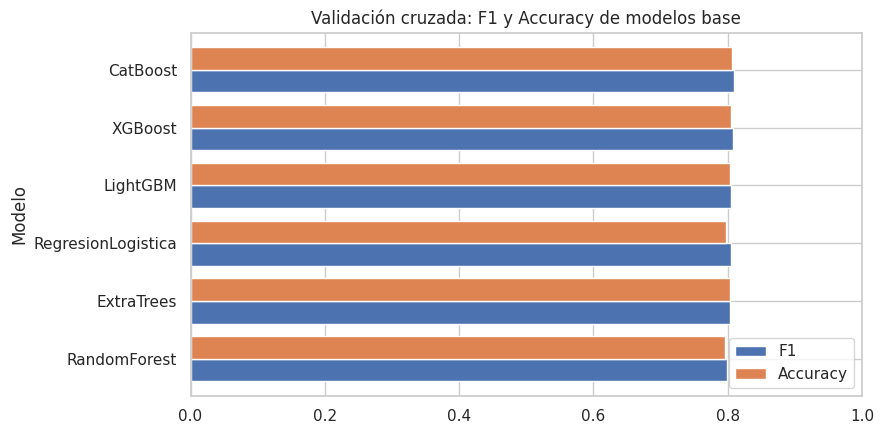

In [11]:
show_df=base_df.sort_values('F1').set_index('Modelo')
ax=show_df[['F1','Accuracy']].plot(kind='barh',figsize=(9,4.5),width=.78)
ax.set_title('Validación cruzada: F1 y Accuracy de modelos base')
ax.set_xlim(0,1)
plt.tight_layout();plt.savefig(OUT/'05_comparacion_modelos.png',dpi=160,bbox_inches='tight');plt.show()

## 9. Experimento B: búsqueda reproducible de hiperparámetros

El conjunto de **desarrollo** se emplea para una búsqueda acotada y documentada. Cada configuración se compara con los mismos 3 folds por grupos; el **holdout no participa**. El espacio no pretende demostrar el óptimo universal, pero mejora la línea base sin fabricar resultados ni usar información del test de Kaggle.

In [12]:
search_space={
'LightGBM':[
    {'n_estimators':450,'learning_rate':.035,'num_leaves':10,'min_child_samples':18,'reg_lambda':3.0},
    {'n_estimators':500,'learning_rate':.035,'num_leaves':23,'min_child_samples':35,'reg_lambda':5.0},
    {'n_estimators':300,'learning_rate':.055,'num_leaves':18,'min_child_samples':22,'reg_lambda':1.0}],
'XGBoost':[
    {'n_estimators':430,'learning_rate':.035,'max_depth':3,'min_child_weight':3,'reg_lambda':5.0},
    {'n_estimators':380,'learning_rate':.05,'max_depth':5,'min_child_weight':5,'reg_lambda':6.0},
    {'n_estimators':500,'learning_rate':.035,'max_depth':4,'min_child_weight':6,'reg_lambda':7.0}],
'CatBoost':[
    {'iterations':540,'depth':5,'learning_rate':.045,'l2_leaf_reg':5},
    {'iterations':600,'depth':6,'learning_rate':.04,'l2_leaf_reg':6},
    {'iterations':420,'depth':7,'learning_rate':.055,'l2_leaf_reg':5}]
}
best_per_family={k:{'f1':metrics(y_dev,v)['F1'],'params':{},'prob':v}
                 for k,v in baseline_oof.items()}
for family,configs in search_space.items():
    for trial,parameters in enumerate(configs,1):
        t0=time.time(); prob=cv_oof(family,parameters)
        measured=metrics(y_dev,prob)
        history.append({'Experimento':f'ajuste_{trial}','Modelo':family,
                        'Parametros':json.dumps(parameters,ensure_ascii=False),**measured})
        print(f'{family:10s} ajuste {trial}  F1={measured["F1"]:.4f} '
              f'accuracy={measured["Accuracy"]:.4f}  tiempo={time.time()-t0:.1f}s',flush=True)
        if measured['F1']>best_per_family[family]['f1']:
            best_per_family[family]={'f1':measured['F1'],'params':parameters,'prob':prob}

cv_results=pd.DataFrame(history).sort_values(['F1','Accuracy'],ascending=False)
cv_results.to_csv(OUT/'comparacion_modelos_cv.csv',index=False,encoding='utf-8-sig')
print('Mejores configuraciones por familia:')
family_best=pd.DataFrame([{'Modelo':k,**metrics(y_dev,v['prob']),
                           'Parametros':json.dumps(v['params'])}
                          for k,v in best_per_family.items()]).sort_values('F1',ascending=False)
display(family_best[['Modelo','F1','Accuracy','Precision','Recall','ROC_AUC','Parametros']].style.format(precision=4))

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM   ajuste 1  F1=0.8077 accuracy=0.8041  tiempo=0.8s


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (10 outputs left out)

CatBoost   ajuste 2  F1=0.8132 accuracy=0.8100  tiempo=13.5s


CatBoost   ajuste 3  F1=0.8133 accuracy=0.8105  tiempo=14.3s


Mejores configuraciones por familia:


,Modelo,F1,Accuracy,Precision,Recall,ROC_AUC,Parametros
5,CatBoost,0.8133,0.8105,0.8069,0.8198,0.9013,"{""iterations"": 420, ""depth"": 7, ""learning_rate"": 0.055, ""l2_leaf_reg"": 5}"
4,XGBoost,0.8085,0.8030,0.7919,0.8258,0.8968,"{""n_estimators"": 430, ""learning_rate"": 0.035, ""max_depth"": 3, ""min_child_weight"": 3, ""reg_lambda"": 5.0}"
3,LightGBM,0.8077,0.8041,0.7989,0.8167,0.8994,"{""n_estimators"": 450, ""learning_rate"": 0.035, ""num_leaves"": 10, ""min_child_samples"": 18, ""reg_lambda"": 3.0}"
0,RegresionLogistica,0.8043,0.7975,0.7836,0.8261,0.8854,{}
2,ExtraTrees,0.8030,0.8034,0.8106,0.7955,0.8917,{}
1,RandomForest,0.7986,0.7955,0.7923,0.8050,0.8880,{}


## 10. Optimización del umbral y ensamble soft-voting

El valor 0.50 no siempre maximiza F1. Se exploran umbrales de 0.35 a 0.65 **exclusivamente sobre predicciones OOF de desarrollo**. Además se compara mezcla ponderada de probabilidades de los dos mejores algoritmos distintos. Se escoge la mayor F1 en CV (desempate: accuracy). Esta optimización también puede sobreajustar CV; por eso hay una evaluación independiente posterior.

In [13]:
ranking=family_best['Modelo'].tolist()
first,second=ranking[:2]
thresholds=np.round(np.arange(.35,.651,.01),2)
strategies={k:{'type':'single','family':k,'params':best_per_family[k]['params'],
               'oof':best_per_family[k]['prob']} for k in ranking}
for weight in [.25,.5,.75]:
    name=f'Ensamble_{first}_{second}_{weight:.2f}'
    prob=weight*best_per_family[first]['prob']+(1-weight)*best_per_family[second]['prob']
    strategies[name]={'type':'blend','families':[first,second],
                      'weights':[float(weight),float(1-weight)],'oof':prob}

threshold_table=[]
for name,info in strategies.items():
    scores=[(float(t),metrics(y_dev,info['oof'],float(t))) for t in thresholds]
    best_t,best_values=max(scores,key=lambda z:(z[1]['F1'],z[1]['Accuracy']))
    threshold_table.append({'Estrategia':name,'Umbral':best_t,**best_values})
strategy_df=pd.DataFrame(threshold_table).sort_values(['F1','Accuracy'],ascending=False).reset_index(drop=True)
strategy_df.to_csv(OUT/'seleccion_umbral_cv.csv',index=False,encoding='utf-8-sig')
display(strategy_df[['Estrategia','Umbral','F1','Accuracy','Precision','Recall','ROC_AUC']].style.format(precision=4))
selected_name=strategy_df.iloc[0]['Estrategia']
selected=strategies[selected_name]
optimal_threshold=float(strategy_df.iloc[0]['Umbral'])
print('SELECCIONADO (sólo CV):',selected_name, '| umbral:',optimal_threshold)
# Una segunda selección, independiente, optimiza Accuracy (metrica oficial de Kaggle).
# No usa ni las etiquetas del holdout ni las predicciones del test de Kaggle.
accuracy_candidates=[]
for sname, sinfo in strategies.items():
    ts=[(float(t),metrics(y_dev,sinfo['oof'],float(t))) for t in thresholds]
    acc_t,acc_m=max(ts,key=lambda z:(z[1]['Accuracy'],z[1]['F1']))
    accuracy_candidates.append({'Estrategia':sname,'Umbral':acc_t,**acc_m})
accuracy_df=pd.DataFrame(accuracy_candidates).sort_values(['Accuracy','F1'],ascending=False).reset_index(drop=True)
accuracy_df.to_csv(OUT/'seleccion_accuracy_cv.csv',index=False,encoding='utf-8-sig')
accuracy_name=accuracy_df.iloc[0]['Estrategia']
accuracy_info=strategies[accuracy_name]
accuracy_threshold=float(accuracy_df.iloc[0]['Umbral'])
print('SELECCIONADO POR ACCURACY (sólo CV):',accuracy_name,'| umbral:',accuracy_threshold)
display(accuracy_df[['Estrategia','Umbral','Accuracy','F1','Precision','Recall']].head(6).style.format(precision=4))

,Estrategia,Umbral,F1,Accuracy,Precision,Recall,ROC_AUC
0,CatBoost,0.3800,0.8228,0.8087,0.7712,0.8818,0.9013
1,Ensamble_CatBoost_XGBoost_0.75,0.4000,0.8228,0.8092,0.7729,0.8795,0.9015
2,Ensamble_CatBoost_XGBoost_0.50,0.3800,0.8219,0.8057,0.7633,0.8903,0.9009
3,Ensamble_CatBoost_XGBoost_0.25,0.3800,0.8206,0.8036,0.7597,0.8921,0.8994
4,LightGBM,0.3700,0.8195,0.8020,0.7576,0.8923,0.8994
5,XGBoost,0.4000,0.8180,0.8013,0.7592,0.8866,0.8968
6,ExtraTrees,0.3900,0.8146,0.8001,0.7643,0.8721,0.8917
7,RandomForest,0.3600,0.8122,0.7936,0.7497,0.8861,0.8880
8,RegresionLogistica,0.3700,0.8122,0.7934,0.7489,0.8872,0.8854


SELECCIONADO (sólo CV): CatBoost | umbral: 0.38


SELECCIONADO POR ACCURACY (sólo CV): CatBoost | umbral: 0.47


,Estrategia,Umbral,Accuracy,F1,Precision,Recall
0,CatBoost,0.4700,0.8109,0.8169,0.7972,0.8375
1,Ensamble_CatBoost_XGBoost_0.75,0.4700,0.8103,0.8175,0.7929,0.8438
2,Ensamble_CatBoost_XGBoost_0.50,0.4700,0.8093,0.8171,0.7903,0.8458
3,Ensamble_CatBoost_XGBoost_0.25,0.4600,0.8082,0.8179,0.7836,0.8552
4,LightGBM,0.4600,0.8056,0.8145,0.7838,0.8478
5,XGBoost,0.4600,0.8054,0.8158,0.7795,0.8558


### Diagnóstico de sobreajuste: curva de aprendizaje

Tomamos el primer fold de CV interno y entrenamos el clasificador elegido con varias fracciones del entrenamiento. La validación permanece en grupos totalmente independientes. Se grafica F1 de entrenamiento (esperablemente mayor) frente a F1 de validación. **No se emplea el holdout.**

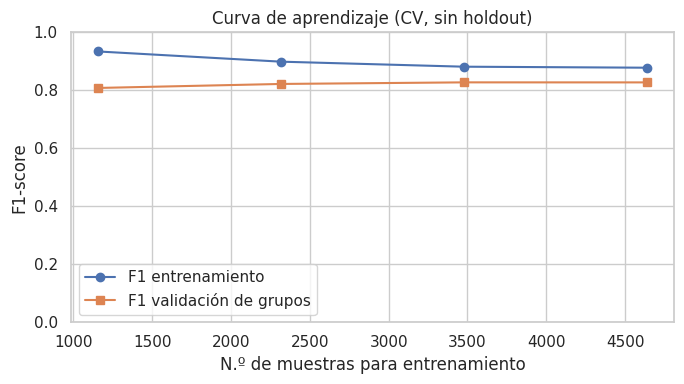

F1 de validación por tamaños: [(1159, 0.8082), (2318, 0.822), (3477, 0.8274), (4636, 0.8273)]


In [14]:
# Curva de aprendizaje ligera usando el primer fold y 4 tamaños.
tr_idx,va_idx=cv_splits[0]
fracs=[.25,.5,.75,1.0]
train_curve=[]; val_curve=[]; sizes=[]
rng=np.random.default_rng(SEED)
for frac in fracs:
    chosen=rng.choice(tr_idx,size=max(30,int(len(tr_idx)*frac)),replace=False)
    if selected['type']=='single':
        cf=selected['family']; cw=[(cf,fit_candidate(cf,selected['params'],X_dev.iloc[chosen],y_dev.iloc[chosen]),1.0)]
    else:
        cw=[(cf,fit_candidate(cf,best_per_family[cf]['params'],X_dev.iloc[chosen],y_dev.iloc[chosen]),w)
            for cf,w in zip(selected['families'],selected['weights'])]
    p_train=sum(w*prob_candidate(cf,model,X_dev.iloc[chosen]) for cf,model,w in cw)
    p_val=sum(w*prob_candidate(cf,model,X_dev.iloc[va_idx]) for cf,model,w in cw)
    train_curve.append(f1_score(y_dev.iloc[chosen],p_train>=optimal_threshold))
    val_curve.append(f1_score(y_dev.iloc[va_idx],p_val>=optimal_threshold))
    sizes.append(len(chosen))
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(sizes,train_curve,'o-',label='F1 entrenamiento')
ax.plot(sizes,val_curve,'s-',label='F1 validación de grupos')
ax.set(xlabel='N.º de muestras para entrenamiento',ylabel='F1-score',title='Curva de aprendizaje (CV, sin holdout)')
ax.set_ylim(0,1);ax.legend();fig.tight_layout()
fig.savefig(OUT/'06_curva_aprendizaje.png',dpi=160,bbox_inches='tight');plt.show()
print('F1 de validación por tamaños:',[(size,round(sc,4)) for size,sc in zip(sizes,val_curve)])

## 11. Evaluación **final** de holdout: una sola vez

Con los parámetros elegidos en CV, se vuelve a entrenar sobre **todo el desarrollo** y se realiza **una** predicción en los grupos reservados. Aquí se reportan precision, recall, F1, accuracy, specificity, macro-F1, balanced accuracy, ROC-AUC, PR-AUC y pérdida logarítmica; además de la matriz de confusión. No se utilizará este resultado para reajustar el umbral ni escoger otra estrategia.

VALIDACIÓN FINAL DE HOLDOUT:


,Valor
F1,0.8163
Accuracy,0.8010
Precision,0.7629
Recall,0.8779
Especificidad,0.7231
F1_macro,0.7996
BalancedAccuracy,0.8005
ROC_AUC,0.9070
PR_AUC,0.9206
LogLoss,0.3736


                 precision    recall  f1-score   support

No transportado     0.8536    0.7231    0.7829       863
   Transportado     0.7629    0.8779    0.8163       876

       accuracy                         0.8010      1739
      macro avg     0.8083    0.8005    0.7996      1739
   weighted avg     0.8079    0.8010    0.7998      1739

Matriz de confusión [[TN,FP],[FN,TP]]: [[624, 239], [107, 769]]


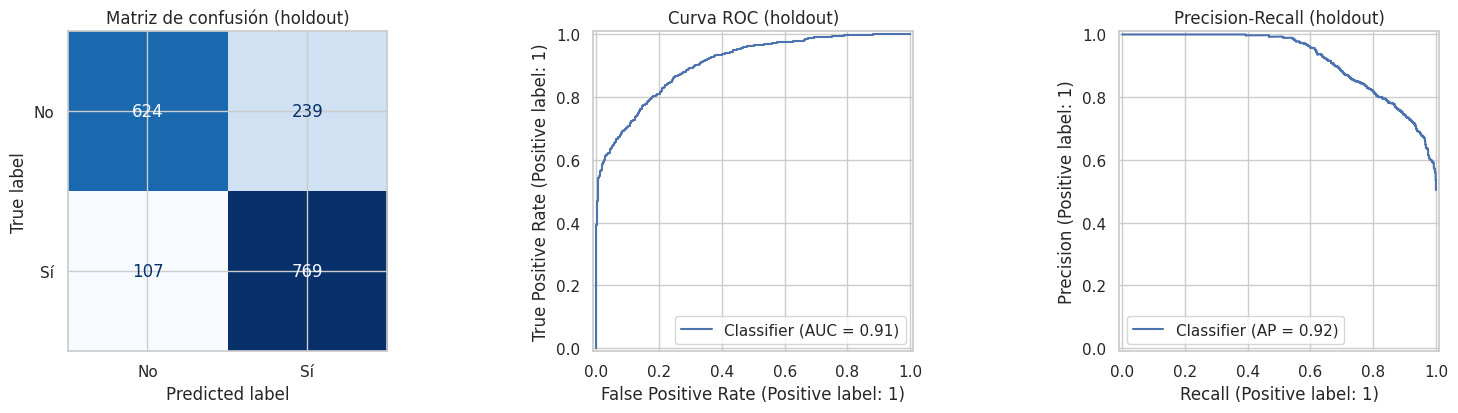

HOLDOUT de estrategia seleccionada por Accuracy: CatBoost


,Accuracy-optimizado
F1,0.8138
Accuracy,0.8079
Precision,0.7952
Recall,0.8333
Especificidad,0.7822
F1_macro,0.8077
BalancedAccuracy,0.8077
ROC_AUC,0.9070
PR_AUC,0.9206
LogLoss,0.3736


In [15]:
def fit_strategy(info,X,y):
    if info['type']=='single':
        fam=info['family']
        return [(fam,fit_candidate(fam,info['params'],X,y),1.0)]
    trained=[]
    for fam,w in zip(info['families'],info['weights']):
        trained.append((fam,fit_candidate(fam,best_per_family[fam]['params'],X,y),w))
    return trained

def predict_strategy(trained,X):
    return sum(weight*prob_candidate(fam,model,X) for fam,model,weight in trained)

trained_hold=fit_strategy(selected,X_dev,y_dev)
prob_hold=predict_strategy(trained_hold,X_hold)
final_hold=metrics(y_hold,prob_hold,optimal_threshold)
pred_hold=(prob_hold>=optimal_threshold).astype(int)
print('VALIDACIÓN FINAL DE HOLDOUT:')
display(pd.DataFrame([final_hold],index=['Holdout']).T.rename(columns={'Holdout':'Valor'}).style.format(precision=4))
print(classification_report(y_hold,pred_hold,target_names=['No transportado','Transportado'],digits=4,zero_division=0))
pd.DataFrame([{'Estrategia':selected_name,'Umbral':optimal_threshold,
               'Muestras':len(y_hold),**final_hold}]).to_csv(OUT/'metricas_holdout.csv',index=False)
cm=confusion_matrix(y_hold,pred_hold,labels=[0,1])
print('Matriz de confusión [[TN,FP],[FN,TP]]:',cm.tolist())
fig,axs=plt.subplots(1,3,figsize=(16,4.3))
ConfusionMatrixDisplay(cm,display_labels=['No','Sí']).plot(ax=axs[0],cmap='Blues',colorbar=False)
axs[0].set_title('Matriz de confusión (holdout)')
RocCurveDisplay.from_predictions(y_hold,prob_hold,ax=axs[1]);axs[1].set_title('Curva ROC (holdout)')
PrecisionRecallDisplay.from_predictions(y_hold,prob_hold,ax=axs[2]);axs[2].set_title('Precision-Recall (holdout)')
fig.tight_layout();fig.savefig(OUT/'03_evaluacion_holdout.png',dpi=160,bbox_inches='tight');plt.show()
# Auditoria secundaria para la estrategia elegida por ACCURACY en CV.
# Esta comparacion NO altera la seleccion de modelos: ambas se fijaron antes del holdout.
trained_accuracy_hold=(trained_hold if selected_name==accuracy_name else
                       fit_strategy(accuracy_info,X_dev,y_dev))
prob_accuracy_hold=predict_strategy(trained_accuracy_hold,X_hold)
accuracy_hold=metrics(y_hold,prob_accuracy_hold,accuracy_threshold)
print('HOLDOUT de estrategia seleccionada por Accuracy:',accuracy_name)
display(pd.DataFrame([accuracy_hold],index=['Accuracy-optimizado']).T.style.format(precision=4))
pd.DataFrame([{'Estrategia':accuracy_name,'Umbral':accuracy_threshold,
               'Muestras':len(y_hold),**accuracy_hold}]).to_csv(OUT/'metricas_holdout_accuracy.csv',index=False)

## 12. Interpretación: importancia de variables (si hay modelo compatible)

Para un bosque/boosting el atributo `feature_importances_` indica contribución aproximada, **no causalidad**. Cuando el modelo ganador es un ensamble se representa el primer miembro compatible; en CatBoost la importancia se calcula sobre categorías originales; en LightGBM/XGBoost el One-Hot expande variables.

,Importancia
HomePlanet,11.011433
Deck,10.198376
ShareFoodCourt,7.355974
Side,6.124881
CryoSleep,5.773308
LuxurySpend,5.512160
CabinNumber,4.976501
CabinSector,4.556561
LogTotalSpend,3.332386
Destination,3.081835


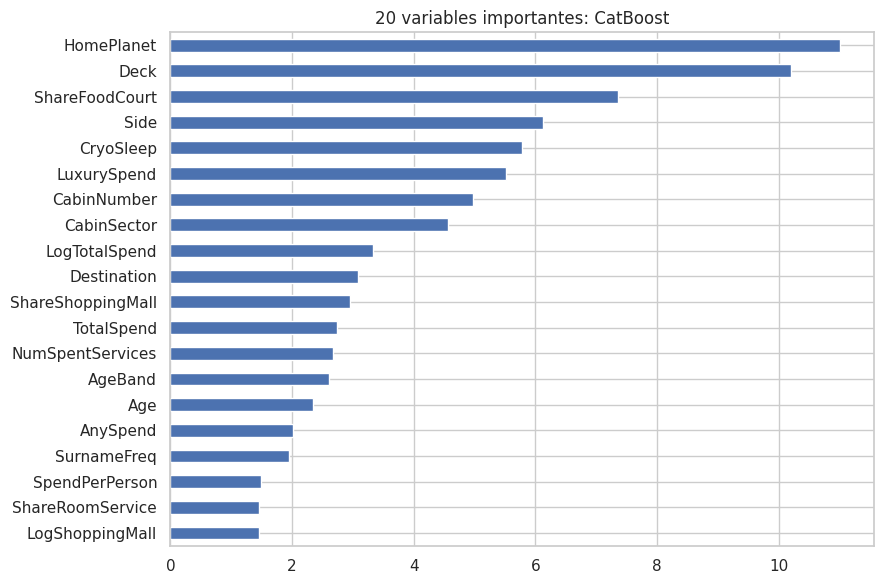

In [16]:
chosen_family,chosen_model,_=trained_hold[0]
if chosen_family=='CatBoost':
    imp=pd.Series(chosen_model.get_feature_importance(),index=X_dev.columns)
elif isinstance(chosen_model,Pipeline) and hasattr(chosen_model.named_steps['modelo'],'feature_importances_'):
    feature_names=chosen_model.named_steps['preparacion'].get_feature_names_out()
    imp=pd.Series(chosen_model.named_steps['modelo'].feature_importances_,index=feature_names)
elif isinstance(chosen_model,Pipeline) and hasattr(chosen_model.named_steps['modelo'],'coef_'):
    feature_names=chosen_model.named_steps['preparacion'].get_feature_names_out()
    imp=pd.Series(np.abs(chosen_model.named_steps['modelo'].coef_[0]),index=feature_names)
else:
    imp=pd.Series(dtype=float)
if len(imp):
    importance=imp.sort_values(ascending=False).head(20)
    display(importance.rename('Importancia').to_frame())
    fig,ax=plt.subplots(figsize=(9,6))
    importance.sort_values().plot(kind='barh',ax=ax)
    ax.set_title(f'20 variables importantes: {chosen_family}')
    fig.tight_layout();fig.savefig(OUT/'04_importancia_features.png',dpi=150,bbox_inches='tight');plt.show()
else:
    print('Este modelo no expone importancias directamente.')

## 13. Entrenamiento definitivo con TODAS las etiquetas y predicción del test de Kaggle

Después de completar la evaluación independiente, la estrategia seleccionada se entrena nuevamente con **las 8,693 etiquetas**, usando los mismos parámetros y umbral de CV. La puntuación de holdout **no** describe este modelo reentrenado de forma independiente; sirve como estimación honesta de generalización del procedimiento. El CSV mantiene orden, IDs y tipo booleano solicitados por Kaggle.

**Dos envíos:** `submission_spaceship_titanic.csv` optimiza F1 y `submission_kaggle_accuracy.csv` optimiza accuracy, la métrica oficial de Kaggle.

In [17]:
trained_final=fit_strategy(selected,X_all,y_all)
prob_kaggle=predict_strategy(trained_final,X_kaggle)
pred_kaggle=(prob_kaggle>=optimal_threshold)
submission=sample.copy()
assert len(submission)==len(test_raw)
assert submission['PassengerId'].astype(str).tolist()==test_raw['PassengerId'].astype(str).tolist()
submission['Transported']=pred_kaggle.astype(bool)
assert list(submission.columns)==['PassengerId','Transported']
assert not submission['Transported'].isna().any()
submission.to_csv(OUT/'submission_spaceship_titanic.csv',index=False)
pd.DataFrame({'PassengerId':test_raw['PassengerId'],'Probabilidad_Transported':prob_kaggle,
              'Prediccion':pred_kaggle}).to_csv(OUT/'probabilidades_test.csv',index=False)
print('CSV de Kaggle creado:',OUT/'submission_spaceship_titanic.csv')
print('Número de predicciones:',len(submission),'| proporción Transported:',round(submission.Transported.mean(),4))
display(submission.head(10))
# Alternativa de envio orientada a Accuracy (Kaggle califica por exactitud).
trained_accuracy_final=(trained_final if accuracy_name==selected_name else
                        fit_strategy(accuracy_info,X_all,y_all))
prob_accuracy_test=predict_strategy(trained_accuracy_final,X_kaggle)
submission_accuracy=sample.copy()
submission_accuracy['Transported']=(prob_accuracy_test>=accuracy_threshold).astype(bool)
assert submission_accuracy['PassengerId'].equals(test_raw['PassengerId'])
submission_accuracy.to_csv(OUT/'submission_kaggle_accuracy.csv',index=False)
print('CSV alternativo para maximizar accuracy:',OUT/'submission_kaggle_accuracy.csv')

CSV de Kaggle creado: /mnt/data/Spaceship_Titanic_Proyecto_ML/resultados/submission_spaceship_titanic.csv
Número de predicciones: 4277 | proporción Transported: 0.5817


,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True
5,0027_01,True
6,0029_01,True
7,0032_01,True
8,0032_02,True
9,0033_01,True


CSV alternativo para maximizar accuracy: /mnt/data/Spaceship_Titanic_Proyecto_ML/resultados/submission_kaggle_accuracy.csv


## 14. Persistencia y reporte reproducible

Se guarda el modelo o ensamble entrenado, el umbral, las columnas y los metadatos para reproducir las predicciones. Una inferencia posterior requiere aplicar `engineer_features` con un lote de pasajeros, porque los contadores y atributos por grupo proceden de los CSV sin etiqueta. No debe cargarse `test.csv` como un conjunto etiquetado ni interpretarse la proporción de predicciones como accuracy.

In [18]:
artifact={'trained_models':trained_final,'threshold':optimal_threshold,'strategy':selected_name,
          'feature_names':list(X_all.columns),'num_cols':num_cols,'cat_cols':cat_cols,'seed':SEED,
          'metric_holdout':final_hold,'params_by_family':{k:v['params'] for k,v in best_per_family.items()}}
joblib.dump(artifact,MODELS/'modelo_final.joblib',compress=3)
meta={'dataset':{'train':len(train_raw),'test':len(test_raw),'n_features':len(X_all.columns)},
      'selection':{'name':selected_name,'threshold':optimal_threshold},
      'holdout':{k:float(v) for k,v in final_hold.items()},
      'versions':{'python':sys.version.split()[0], 'pandas':pd.__version__}}
with (OUT/'resumen_resultados.json').open('w',encoding='utf-8') as f: json.dump(meta,f,indent=2,ensure_ascii=False)
text=f"""# Resultados del experimento — Spaceship Titanic

- Seleccionado en validación cruzada: **{selected_name}**
- Umbral optimizado en validación cruzada: **{optimal_threshold:.2f}**
- Holdout independiente: **{len(y_hold)}** pasajeros de grupos no vistos

| Métrica | Holdout |
|---|---:|
"""
for k,v in final_hold.items(): text+=f'| {k} | {v:.4f} |\n'
text+="""
La métrica de Kaggle es desconocida hasta evaluar allí `submission_spaceship_titanic.csv`. No se garantiza el óptimo global.
"""
(OUT/'RESUMEN.md').write_text(text,encoding='utf-8')
loaded=joblib.load(MODELS/'modelo_final.joblib')
loaded_probs=predict_strategy(loaded['trained_models'],X_kaggle.head(8))
assert np.allclose(loaded_probs,prob_kaggle[:8]),'El modelo persistido no coincide'
print('Modelo persistido y verificado:',(MODELS/'modelo_final.joblib').name)
print('Resultados guardados:',sorted(p.name for p in OUT.iterdir()))
accuracy_artifact={'trained_models':trained_accuracy_final,'threshold':accuracy_threshold,
                   'strategy':accuracy_name,'metric_holdout':accuracy_hold,
                   'feature_names':list(X_all.columns),'cat_cols':cat_cols,'num_cols':num_cols}
joblib.dump(accuracy_artifact,MODELS/'modelo_accuracy.joblib',compress=3)
accuracy_report="""
## Estrategia alternativa optimizada por accuracy (métrica oficial de Kaggle)

"""
accuracy_report+=f'- Estrategia: **{accuracy_name}**, umbral **{accuracy_threshold:.2f}**\n'
accuracy_report+='\n| Métrica | Holdout optimizado por accuracy |\n|---|---:|\n'
for k,v in accuracy_hold.items(): accuracy_report+=f'| {k} | {v:.4f} |\n'
with (OUT/'RESUMEN.md').open('a',encoding='utf-8') as f:f.write(accuracy_report)
print('Guardado modelo alternativo y reporte de accuracy')

Modelo persistido y verificado: modelo_final.joblib
Resultados guardados: ['01_auditoria.png', '02_exploracion.png', '03_evaluacion_holdout.png', '04_importancia_features.png', '05_comparacion_modelos.png', '06_curva_aprendizaje.png', 'RESUMEN.md', 'auditoria_test.csv', 'auditoria_train.csv', 'comparacion_modelos_cv.csv', 'metricas_holdout.csv', 'metricas_holdout_accuracy.csv', 'probabilidades_test.csv', 'resumen_resultados.json', 'seleccion_accuracy_cv.csv', 'seleccion_umbral_cv.csv', 'submission_kaggle_accuracy.csv', 'submission_spaceship_titanic.csv']
Guardado modelo alternativo y reporte de accuracy


## 15. Conclusiones y notas de rigor

1. El ciclo de vida usado responde al enfoque **CRISP-DM** de las diapositivas. El problema es **clasificación supervisada**, no regresión lineal y tampoco la supervivencia del Titanic histórico.
2. La **imputación** se ajusta solo en los datos de cada entrenamiento (`Pipeline`). Se muestran `StandardScaler` y `MinMaxScaler`; los árboles pueden conservar unidades originales. `OneHotEncoder` maneja categorías nuevas sin modificar el número de columnas.
3. Se usan **splits por grupos**, evitando que un acompañante etiquetado valide a un pasajero del mismo grupo, y se reserva un **holdout no usado** durante selección.
4. Se optimiza **F1 clase positiva** y se presentan accuracy, precision, recall, especificidad, F1 macro, balanced accuracy, ROC-AUC, PR-AUC, log loss, matriz de confusión y curvas.
5. Los campos de texto e ID se convierten en **variables interpretables**, y la ingeniería de grupos se basa solo en predictores, nunca en el target.
6. **Limitaciones:** las estadísticas calculadas en train+test son transductivas (utilizan covariables no etiquetadas). El número de configuraciones de hiperparámetros es finito y el umbral CV tiene incertidumbre; el desempeño oculto de Kaggle puede diferir.

**Archivos generados:** notebook ejecutado, `resultados/submission_spaceship_titanic.csv`, predicciones probabilísticas, tablas de métricas, figuras y `modelos/modelo_final.joblib`. Se incluyen los CSV y las diapositivas originales en sus carpetas para repetir el proyecto.

Hay también una estrategia alternativa seleccionada por accuracy en CV y su archivo CSV independiente, para comparar el conflicto entre métricas sin ajustar con el holdout.